# Predicting Player Data Contribution on a Minecraft Research Server

**DSCI 100 Final Project — September to December 2024**

## Introduction

This project explores which factors influence the amount of time players spend on a Minecraft
server, focusing on demographics such as gender, age, and experience level. Using statistical
methods from DSCI 100, we address the question: **what kind of player is most likely to
contribute a large amount of data?**

The data comes from the PLAI research group at UBC, who run a Minecraft server called PLAICraft
where players can play and interact with each other. Their goal is to gather real player data in
order to train AI Minecraft players, so knowing which players generate the most playtime has
direct value for their recruitment strategy.

### The data

`players.csv` contains 197 observations, each representing a unique player:

| Variable | Type | Description |
| --- | --- | --- |
| `experience` | factor | Player experience level: Beginner, Amateur, Regular, Veteran, Pro |
| `subscribe` | logical | Whether the player is subscribed to the service |
| `hashedEmail` | character | Hashed player email |
| `played_hours` | double | Total hours logged by the player |
| `name` | character | Player name |
| `gender` | factor | Player gender |
| `age` | double | Player age in years |
| `individualId` | logical | Empty column, unused |
| `organizationName` | logical | Empty column, unused |

`individualId` and `organizationName` are empty and are dropped before analysis.

In [1]:
library(tidyverse)
library(ggplot2)
library(dplyr)
library(tidymodels)

# Download the data once, then read from the local copy on subsequent runs.
if (!file.exists("players.csv")) {
  url <- "https://drive.google.com/uc?export=download&id=1Mw9vW0hjTJwRWx0bDXiSpYsO3gKogaPz"
  download.file(url, "players.csv")
}

players_data <- read_csv("players.csv")
players_data

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.1.1 ──

✔ broom        1.0.6     ✔ rsample      1.2.1
✔ dials        1.3.0     ✔ tune         1.1.2
✔ infer        1.0.7     ✔ workflows    1.1.4
✔ modeldata    1.4.0     ✔ workflowsets 1.0.1
✔ parsnip      1.2.1     ✔ yardstick    1.3.1
✔ recipes      1.1.0     

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filt

experience,subscribe,hashedEmail,played_hours,name,gender,age,individualId,organizationName
<chr>,<lgl>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<lgl>,<lgl>
Pro,TRUE,f6daba428a5e19a3d47574858c13550499be23603422e6a0ee9728f8b53e192d,30.3,Morgan,Male,9,NA,NA
Veteran,TRUE,f3c813577c458ba0dfef80996f8f32c93b6e8af1fa939732842f2312358a88e9,3.8,Christian,Male,17,NA,NA
Veteran,FALSE,b674dd7ee0d24096d1c019615ce4d12b20fcbff12d79d3c5a9d2118eb7ccbb28,0.0,Blake,Male,17,NA,NA
Amateur,TRUE,23fe711e0e3b77f1da7aa221ab1192afe21648d47d2b4fa7a5a659ff443a0eb5,0.7,Flora,Female,21,NA,NA
Regular,TRUE,7dc01f10bf20671ecfccdac23812b1b415acd42c2147cb0af4d48fcce2420f3e,0.1,Kylie,Male,21,NA,NA
Amateur,TRUE,f58aad5996a435f16b0284a3b267f973f9af99e7a89bee0430055a44fa92f977,0.0,Adrian,Female,17,NA,NA
Regular,TRUE,8e594b8953193b26f498db95a508b03c6fe1c24bb5251d392c18a0da9a722807,0.0,Luna,Female,19,NA,NA
Amateur,FALSE,1d2371d8a35c8831034b25bda8764539ab7db0f63938696917c447128a2540dd,0.0,Emerson,Male,21,NA,NA
Amateur,TRUE,8b71f4d66a38389b7528bb38ba6eb71157733df7d1740371852a797ae97d82d1,0.1,Natalie,Male,17,NA,NA


## Methods and Results

We use k-nearest-neighbours (KNN) regression to estimate how each variable relates to
`played_hours`, which stands in for the amount of data a player contributes.

### Cleaning the data

`hashedEmail`, `individualId`, and `organizationName` are not useful for analysis, so we remove them.

In [2]:
players_clean1 <- players_data |> 
  select(-hashedEmail, -individualId, -organizationName)
players_clean1

experience,subscribe,played_hours,name,gender,age
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9
Veteran,TRUE,3.8,Christian,Male,17
Veteran,FALSE,0.0,Blake,Male,17
Amateur,TRUE,0.7,Flora,Female,21
Regular,TRUE,0.1,Kylie,Male,21
Amateur,TRUE,0.0,Adrian,Female,17
Regular,TRUE,0.0,Luna,Female,19
Amateur,FALSE,0.0,Emerson,Male,21
Amateur,TRUE,0.1,Natalie,Male,17


We combine the sparse gender categories, since "Non-binary" covers genders that are not male or female.

In [3]:
players_clean2 <- players_clean1 |>
  mutate(gender = case_when(gender == "Non-binary" | gender == "Two-Spirited"  | gender == "Agender" | gender == "Other" ~ "Non-binary", TRUE ~ gender))
players_clean2

experience,subscribe,played_hours,name,gender,age
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9
Veteran,TRUE,3.8,Christian,Male,17
Veteran,FALSE,0.0,Blake,Male,17
Amateur,TRUE,0.7,Flora,Female,21
Regular,TRUE,0.1,Kylie,Male,21
Amateur,TRUE,0.0,Adrian,Female,17
Regular,TRUE,0.0,Luna,Female,19
Amateur,FALSE,0.0,Emerson,Male,21
Amateur,TRUE,0.1,Natalie,Male,17


Players who answered "Prefer not to say" for gender do not help with predicting which type of
player is likely to contribute more data, so we remove them from the analysis.

In [4]:
players_clean3 <- players_clean2 |>
  filter(gender != "Prefer not to say")
players_clean3

experience,subscribe,played_hours,name,gender,age
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9
Veteran,TRUE,3.8,Christian,Male,17
Veteran,FALSE,0.0,Blake,Male,17
Amateur,TRUE,0.7,Flora,Female,21
Regular,TRUE,0.1,Kylie,Male,21
Amateur,TRUE,0.0,Adrian,Female,17
Regular,TRUE,0.0,Luna,Female,19
Amateur,FALSE,0.0,Emerson,Male,21
Amateur,TRUE,0.1,Natalie,Male,17


KNN regression requires numeric predictors. We encode experience level as an ordinal variable
from 0 to 4:

| Code | Experience |
| --- | --- |
| 0 | Beginner |
| 1 | Amateur |
| 2 | Regular |
| 3 | Veteran |
| 4 | Pro |

This assumes the gap between adjacent levels is roughly equal, which is a simplification worth
keeping in mind when interpreting the results.

In [5]:
players_clean4 <- players_clean3 |>
  mutate(experience_numeric = 
         case_when(experience == "Pro" ~ 4, experience == "Veteran" ~ 3, experience == "Regular" ~ 2, experience == "Amateur" ~ 1, experience == "Beginner" ~ 0, TRUE ~ NA_real_))
players_clean4

experience,subscribe,played_hours,name,gender,age,experience_numeric
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9,4
Veteran,TRUE,3.8,Christian,Male,17,3
Veteran,FALSE,0.0,Blake,Male,17,3
Amateur,TRUE,0.7,Flora,Female,21,1
Regular,TRUE,0.1,Kylie,Male,21,2
Amateur,TRUE,0.0,Adrian,Female,17,1
Regular,TRUE,0.0,Luna,Female,19,2
Amateur,FALSE,0.0,Emerson,Male,21,1
Amateur,TRUE,0.1,Natalie,Male,17,1


Subscription status is already binary, so we convert it directly to 0 and 1.

In [6]:
players_clean5 <- players_clean4 |>
  mutate(subscribe_binary = as.numeric(subscribe))
players_clean5

experience,subscribe,played_hours,name,gender,age,experience_numeric,subscribe_binary
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9,4,1
Veteran,TRUE,3.8,Christian,Male,17,3,1
Veteran,FALSE,0.0,Blake,Male,17,3,0
Amateur,TRUE,0.7,Flora,Female,21,1,1
Regular,TRUE,0.1,Kylie,Male,21,2,1
Amateur,TRUE,0.0,Adrian,Female,17,1,1
Regular,TRUE,0.0,Luna,Female,19,2,1
Amateur,FALSE,0.0,Emerson,Male,21,1,0
Amateur,TRUE,0.1,Natalie,Male,17,1,1


### Exploratory visualisation

Before modelling, we look at how playtime varies across each of the four candidate predictors.

Total playtime broken down by experience level.

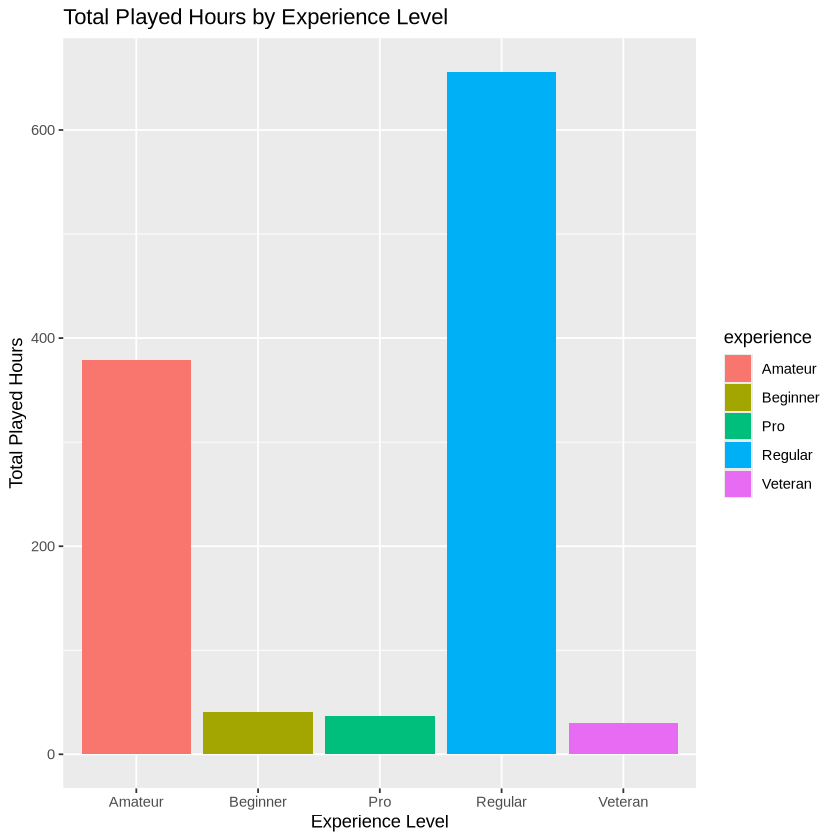

In [ ]:
# Plot 1: total played hours by experience level
grouped_data_experience <- players_clean3 |>
  group_by(experience) |>
  summarise(total_played_hours = sum(played_hours, na.rm = TRUE))

ggplot(grouped_data_experience, aes(x = experience, y = total_played_hours, fill = experience)) +
  geom_bar(stat = "identity") +
  labs(title = "Total Played Hours by Experience Level",
       x = "Experience Level",
       y = "Total Played Hours")

Total playtime broken down by gender. Note that group sizes are very uneven, which is why the
next plot looks at the average instead.

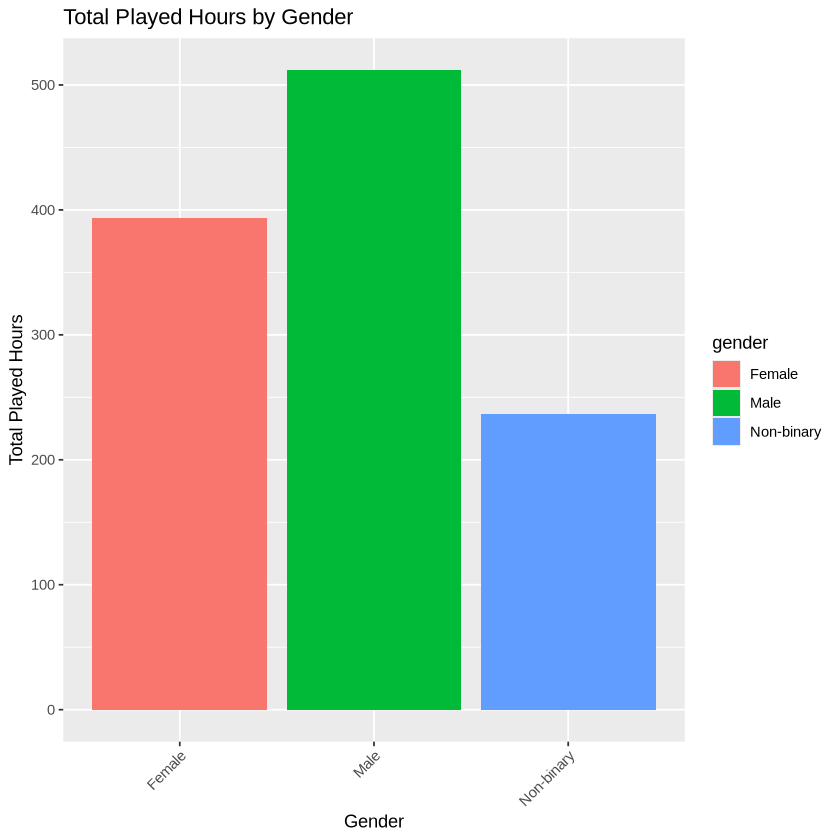

In [ ]:
# Plot 2: total played hours by gender
grouped_data_gender <- players_clean3 |>
  group_by(gender) |>
  summarise(total_played_hours = sum(played_hours, na.rm = TRUE))

ggplot(grouped_data_gender, aes(x = gender, y = total_played_hours, fill = gender)) +
  geom_bar(stat = "identity") +
  labs(title = "Total Played Hours by Gender",
       x = "Gender",
       y = "Total Played Hours") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

Average playtime per player by gender, which controls for the uneven group sizes above.

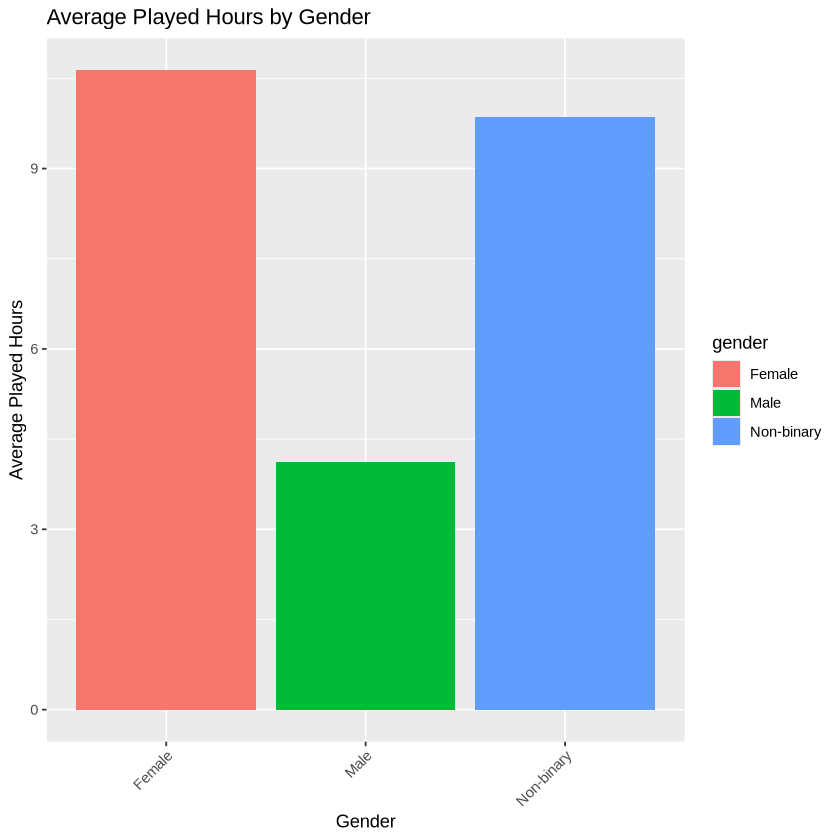

In [ ]:
# Plot 3: average played hours by gender
grouped_data_avg <- players_clean3 |>
  group_by(gender) |>
  summarise(average_played_hours = mean(played_hours, na.rm = TRUE))

ggplot(grouped_data_avg, aes(x = gender, y = average_played_hours, fill = gender)) +
  geom_bar(stat = "identity") +
  labs(title = "Average Played Hours by Gender",
       x = "Gender",
       y = "Average Played Hours") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

Playtime by subscription status.

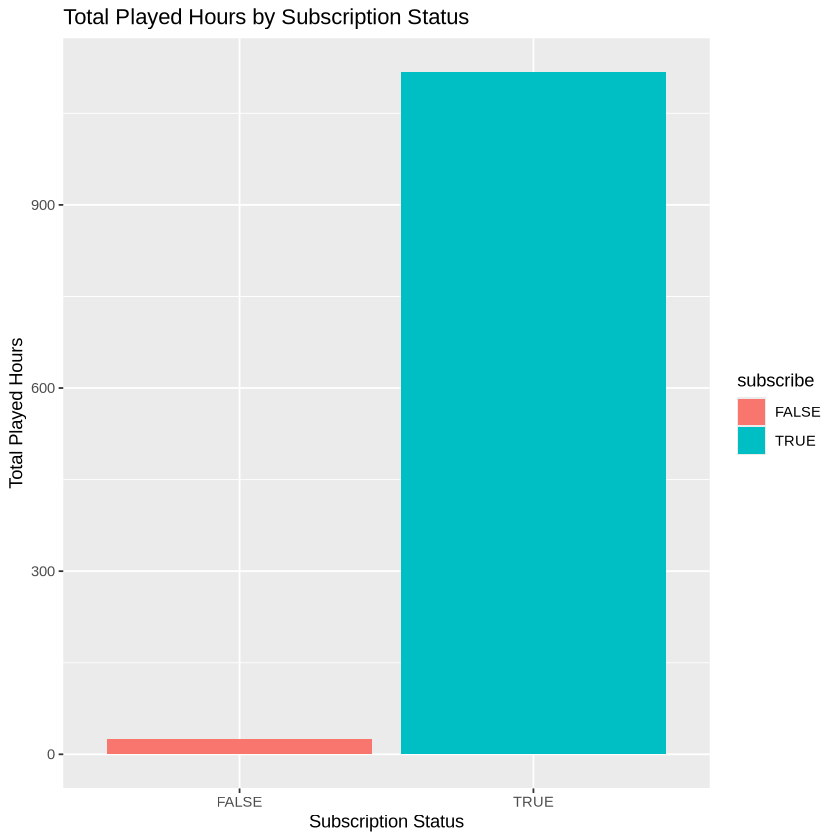

In [ ]:
# Plot 4: total played hours by subscription status
ggplot(players_clean3, aes(x = subscribe, y = played_hours, fill = subscribe)) +
  geom_bar(stat = "identity") +
  labs(title = "Total Played Hours by Subscription Status",
       x = "Subscription Status",
       y = "Total Played Hours")

Playtime against age, split by gender. Playtime is plotted on a log scale because the
distribution is heavily concentrated near zero; a small constant is added so that players with
zero hours still appear.

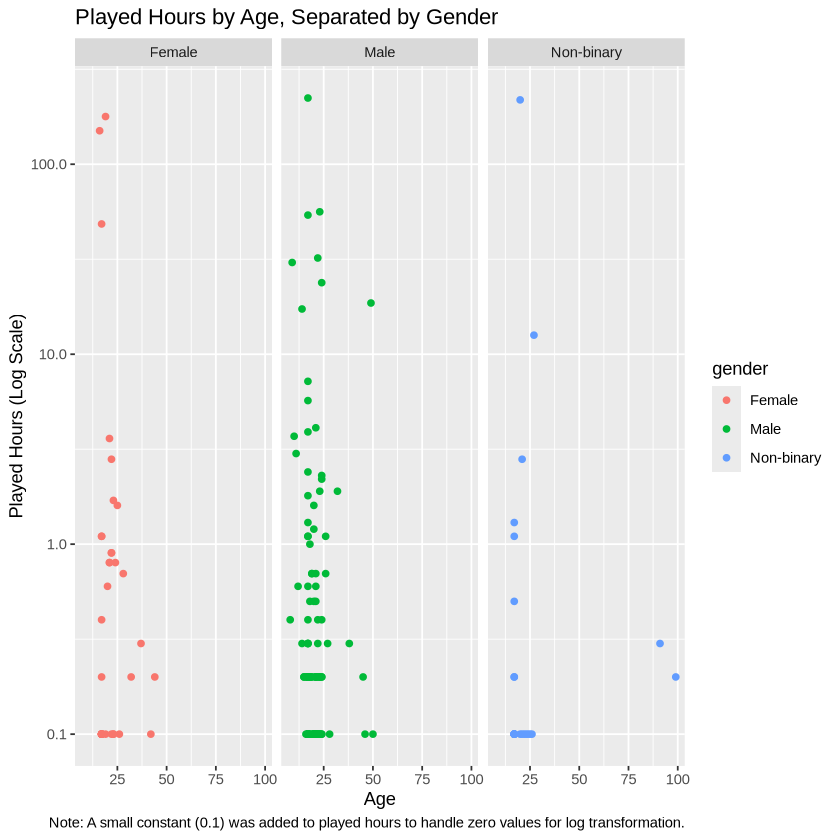

In [ ]:
# Plot 5: played hours by age, faceted by gender
account_for_log0 <- players_clean3 |>
  mutate(played_hours_log = played_hours + 0.1)  # avoid log(0)

ggplot(account_for_log0, aes(x = age, y = played_hours_log, color = gender)) +
  geom_point() +
  scale_y_log10() +
  facet_wrap(~ gender) +
  labs(
    title = "Played Hours by Age, Separated by Gender",
    x = "Age",
    y = "Played Hours (Log Scale)",
    caption = "Note: a small constant (0.1) was added to played hours to handle zero values under the log transformation.")

Average playtime per player by experience level.

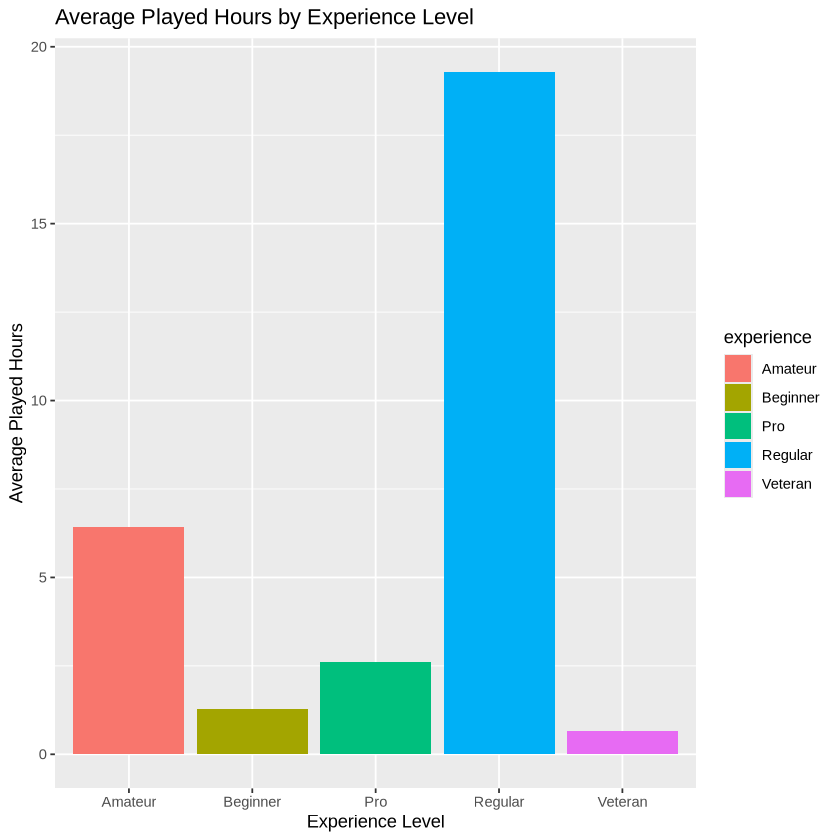

In [ ]:
# Plot 6: average played hours by experience level
grouped_experience <- players_clean3 |>
  group_by(experience) |>
  summarise(average_played_hours = mean(played_hours, na.rm = TRUE))

ggplot(grouped_experience, aes(x = experience, y = average_played_hours, fill = experience)) +
  geom_bar(stat = "identity") +
  labs(title = "Average Played Hours by Experience Level",
       x = "Experience Level",
       y = "Average Played Hours")

The distribution of playtime across all players. Almost all players log close to zero hours,
with a small number of extreme outliers. This shape matters for the modelling that follows.

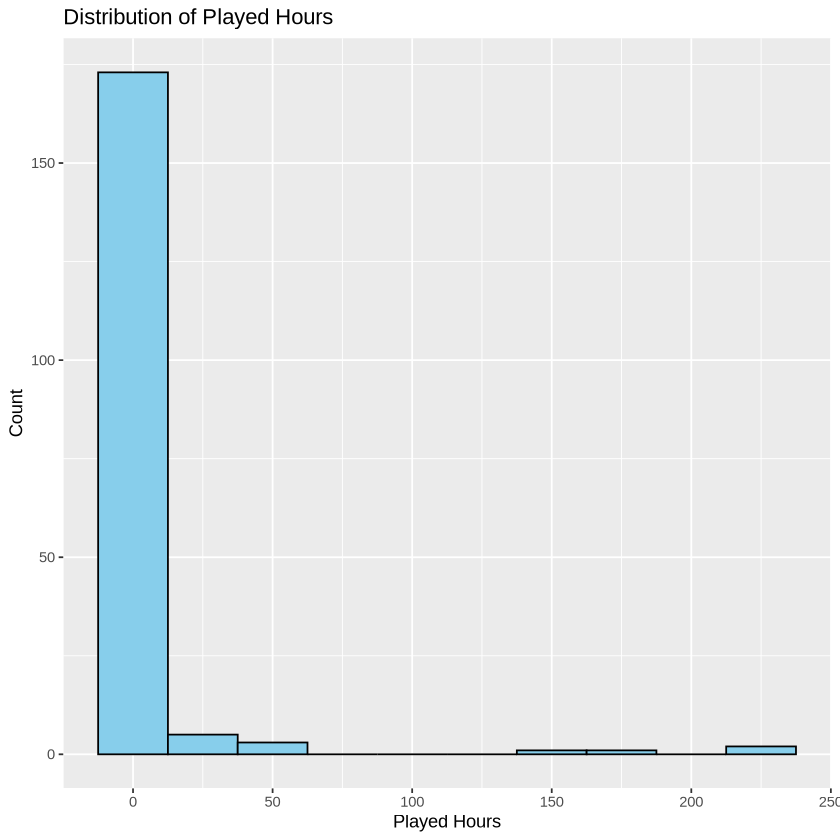

In [ ]:
# Plot 7: distribution of played hours
ggplot(players_clean3, aes(x = played_hours)) +
  geom_histogram(binwidth = 25, fill = "skyblue", color = "black") +
  labs(title = "Distribution of Played Hours",
       x = "Played Hours",
       y = "Count")

### KNN regression

We now fit the model. Note that `gender` is **not** used as a predictor: it is a categorical
variable with no natural ordinal encoding, so it is dropped here along with the other non-numeric
columns. The gender findings reported in the discussion come from the exploratory plots above,
not from the model.

The predictors used are `age`, `experience_numeric`, and `subscribe_binary`.

In [8]:
plai_data = players_clean5 |>
select(-experience, -subscribe, -name, -gender)
plai_data
players_clean5

played_hours,age,experience_numeric,subscribe_binary
<dbl>,<dbl>,<dbl>,<dbl>
30.3,9,4,1
3.8,17,3,1
0.0,17,3,0
0.7,21,1,1
0.1,21,2,1
0.0,17,1,1
0.0,19,2,1
0.0,21,1,0
0.1,17,1,1


experience,subscribe,played_hours,name,gender,age,experience_numeric,subscribe_binary
<chr>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Pro,TRUE,30.3,Morgan,Male,9,4,1
Veteran,TRUE,3.8,Christian,Male,17,3,1
Veteran,FALSE,0.0,Blake,Male,17,3,0
Amateur,TRUE,0.7,Flora,Female,21,1,1
Regular,TRUE,0.1,Kylie,Male,21,2,1
Amateur,TRUE,0.0,Adrian,Female,17,1,1
Regular,TRUE,0.0,Luna,Female,19,2,1
Amateur,FALSE,0.0,Emerson,Male,21,1,0
Amateur,TRUE,0.1,Natalie,Male,17,1,1


We split the data 75/25, stratifying on `played_hours` so that both splits cover a similar range
of the heavily skewed target.

In [9]:
set.seed(1000)
plai_split <- initial_split(plai_data, prop = 0.75, strata = played_hours)
plai_train <- training(plai_split)
plai_test <- testing(plai_split)

We tune k using 5-fold cross-validation on the training set, centring and scaling the predictors
inside the recipe so that no single variable dominates the distance calculation.

The search grid runs from 1 to 10. As the RMSE plot below shows, cross-validated error is still
falling at k = 10, which is the largest value in the grid — so the selected k sits at the boundary
of the search and the true optimum lies somewhere beyond it. Widening the grid is noted in the
limitations below as the clearest next step.

In [10]:
set.seed(1000) # Seed Set
plai_knn_recipe <- recipe(played_hours ~., data = plai_train)|>
step_center(all_predictors())|>
step_scale(all_predictors())

plai_knn_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = tune()) |>
                      set_engine("kknn") |>
                      set_mode("regression")

plai_vfold <- vfold_cv(plai_train, v = 5, strata = played_hours)

plai_knn_workflow <- workflow() |>
                        add_recipe(plai_knn_recipe) |>
                        add_model(plai_knn_spec)

gridvals <- tibble(neighbors = seq(1,10))

plai_knn_results <- plai_knn_workflow |>
                       tune_grid(resamples = plai_vfold, grid = gridvals) |>
                       collect_metrics() 

kmin <- plai_knn_results |>
               filter(.metric == 'rmse') |>
               filter(mean == min(mean))  |> 
               pull(neighbors)

kmin
plai_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = kmin) |>
  set_engine("kknn") |>
  set_mode("regression")

plai_fit <- workflow() |>
  add_recipe(plai_knn_recipe) |>
  add_model(plai_spec) |>
  fit(data = plai_train)

plai_pred <- plai_fit |>
  predict(plai_test) |>
  bind_cols(plai_test) |>
  metrics(truth = played_hours, estimate = .pred)

plai_rmspe<- plai_pred|>
  filter(.metric == 'rmse') |>
  pull(.estimate) 
plai_rmspe

[1] 10

[1] 13.08706

Plotting cross-validated RMSE against k shows how the error responds to the choice of neighbours.

neighbors,mean
<int>,<dbl>
1,37.17982
2,32.29609
3,32.94749
4,32.24223
5,33.09927
6,32.67146
7,31.82929
8,31.77740
9,30.37696


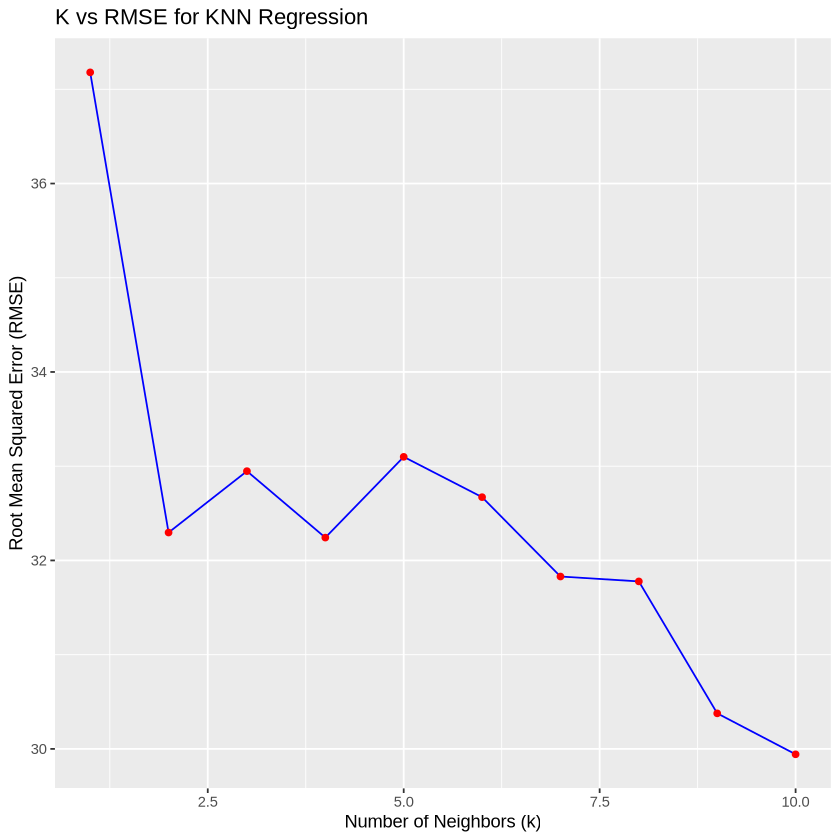

In [11]:
rmse_results <- plai_knn_results |>
  filter(.metric == "rmse") |>
  select(neighbors, mean)

rmse_results


ggplot(rmse_results, aes(x = neighbors, y = mean)) +
  geom_line(color = "blue") +  
  geom_point(color = "red") + 
  labs(title = "K vs RMSE for KNN Regression",
       x = "Number of Neighbors (k)",
       y = "Root Mean Squared Error (RMSE)") 

Finally, we plot the fitted model's predictions across the age range against the observed data.

Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”


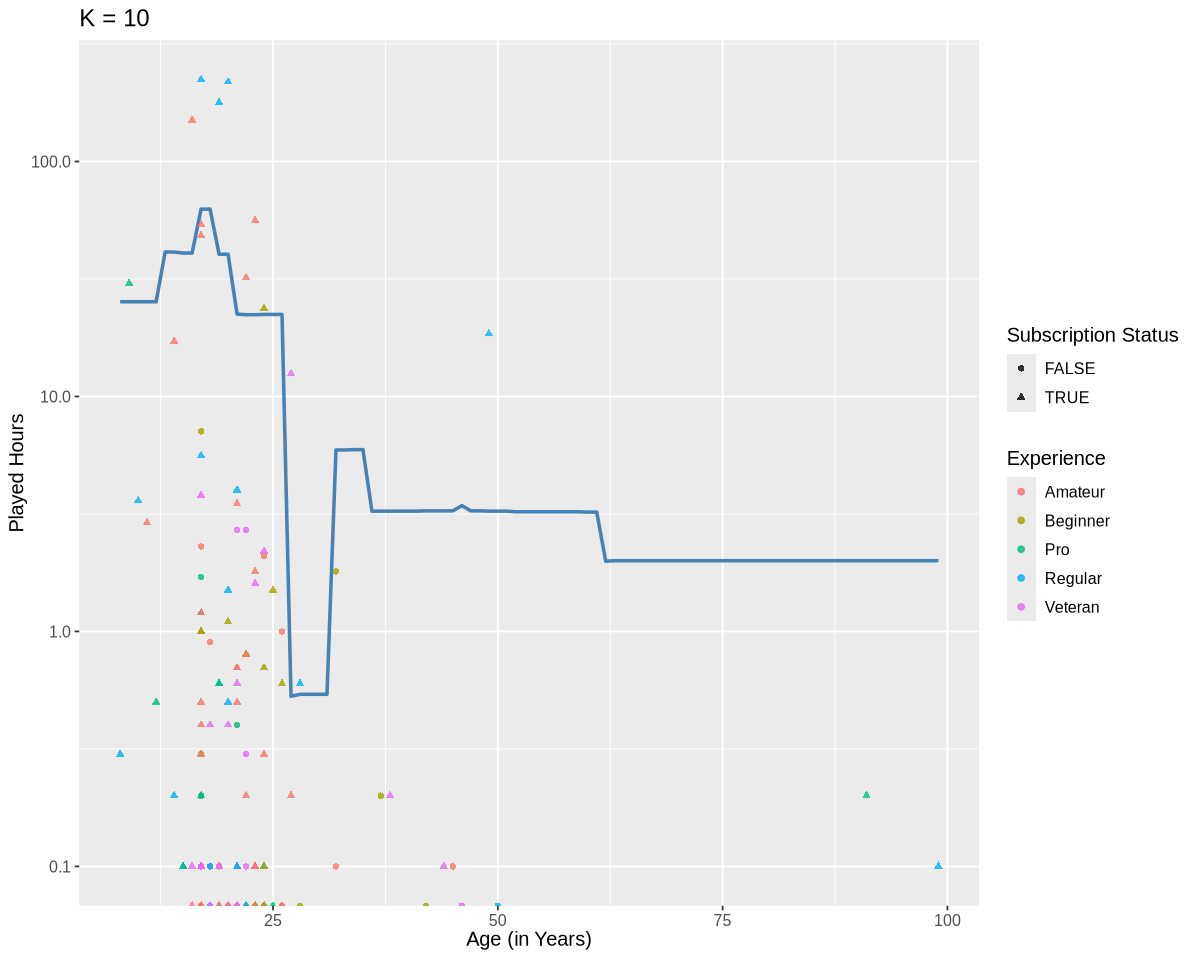

In [12]:
options(repr.plot.width = 10, repr.plot.height = 8)  

age_prediction_grid <- tibble(
  age = seq(from = min(plai_data$age), to = max(plai_data$age), by = 1),
  experience_numeric = mean(plai_data$experience_numeric, na.rm = TRUE),
  subscribe_binary = unique(plai_data$subscribe_binary)[1]
)

plai_preds <- plai_fit |>
  predict(age_prediction_grid) |>
  bind_cols(age_prediction_grid)  
plai_preds <- plai_preds |>
  mutate(subscribe = players_clean5$subscribe[1])

plot_final <- ggplot(players_clean5, aes(x = age, y = played_hours, color = experience, shape = subscribe)) + 
  geom_line(
    data = plai_preds,
    mapping = aes(x = age, y = .pred),
    color = "steelblue",
    linewidth = 1
  ) + 
  geom_point(alpha = 0.8) +
  xlab("Age (in Years)") +
  ylab("Played Hours") +
  labs(
    color = "Experience",
    shape = "Subscription Status"
  ) +
scale_y_log10() +
  ggtitle(paste0("K = ", kmin)) +
  theme(text = element_text(size = 12))

plot_final

## Discussion

### Summary

In our analysis we looked into how various factors affect how much data a player is likely to
contribute, focusing on experience level, gender, subscription status, and age.

**Experience level.** "Regular" players contributed far more playtime than any other group,
averaging roughly 20 hours compared with about 6 hours for the next highest group, "Amateur", an
increase of over 200%. "Veteran", "Pro", and "Beginner" all contributed roughly the same, lower
amount. Regular players therefore look like the most productive group to recruit.

**Gender.** Total and average playtime point in different directions. In total hours, males
contributed the most, followed by females and then non-binary players. But adjusting for the very
uneven group sizes, females and non-binary players contributed roughly 200% more average playtime
per person than males. This suggests that more males contribute overall, while females and
non-binary players contribute more each. Maximising total data collected therefore depends on
whether it is easier to recruit a large number of male players or a smaller number of players who
each contribute more.

**Subscription status.** This was the strongest signal in the data. Subscribed players logged
approximately 950 hours in total compared with about 10 hours for non-subscribed players.

**Age.** Almost all players who logged any playtime were under 50, with contributions above that
age being rare. The sample was also predominantly male, which confirms the imbalance noted above.

**Distribution.** The histogram shows that nearly all players logged close to zero hours, with a
small number of heavy contributors accounting for most of the total.

### Conclusion

Subscribed players at the "Regular" experience level contribute substantially more playtime than
any other group, and most high-contributing players are subscribed. Players aged 25 and under are
more likely to log in and play beyond an hour, and a small number play considerably more.

### Limitations

Several caveats apply to these results.

**The model does not predict playtime well.** The target is heavily zero-inflated: most players
logged close to no hours, while a handful logged dozens. KNN regression averages over neighbours,
so it pulls predictions toward the common near-zero case and cannot anticipate the rare heavy
contributors who account for most of the total playtime. The test RMSE should be read against a
target whose values are mostly near zero, which makes the error substantial in relative terms. A
classification approach, predicting whether a player becomes a high contributor at all, would
likely suit this data better than regression.

**The sample is small and unbalanced.** With 197 players and only a fraction logging meaningful
playtime, the effective sample for the behaviour we care about is much smaller than the raw count
suggests. The non-binary group in particular contains very few players, so the average-playtime
finding for that group rests on a handful of observations and should be treated as provisional.

**Gender was not modelled.** As noted above, gender was used only in the exploratory plots. Any
association between gender and playtime reported here is descriptive, not a model result.

**Experience was treated as evenly spaced.** Encoding experience from 0 to 4 assumes equal gaps
between adjacent levels, which may not reflect how these categories actually differ.

**The k search was too narrow.** Cross-validated RMSE was still decreasing at k = 10, the largest
value in the search grid, so the selected k sits at the boundary and the true optimum was never
located. Re-running with a wider grid is the most direct improvement available to this analysis.

**Correlation, not causation.** Subscription status is strongly associated with playtime, but the
direction is unclear: subscribing may encourage play, or players who already intend to play more
may be the ones who subscribe.

### Expectations

Our findings mostly aligned with our expectations. We anticipated that regular players would
contribute the most playtime and that subscription status would matter, both of which held. The
age findings also matched our expectation that players would skew younger. The gender result was
the surprise: we expected males to lead on total playtime, which they did, but the substantially
higher average playtime among females and non-binary players was not something we predicted.

### Impact

These findings offer a starting point for recruitment strategy by identifying which player
demographics generate the most data. The practical trade-off is between recruiting a large number
of players from the most numerous group and recruiting fewer players who each contribute more,
and which is preferable depends on whether the goal is total hours or hours per participant.

### Future questions

Additional variables might improve prediction considerably: players' gaming history (previous
games or preferred genres), their available free time (hours of school or work per week), or how
they found the server. These could also help explain the higher per-player playtime observed
among female and non-binary participants. Given the shape of the target variable, reframing the
problem as classification, predicting whether a player will become a high contributor, is likely
the more productive next step.